# TB data exploration: images and genomics

This notebook explores the TB dataset under `data/raw/TB/` without assuming that image filenames identify genomic specimens. It inspects the full image tree, official TBX11K labels and splits, the TB Portals genomics table, and the sequenced drug-susceptibility-test (DST) observation table.

**Important data-integrity finding:** the source datasets do not provide an image-to-genomic crosswalk. No genomic identifier examined matches an image filename stem. Consequently, paired-sample analyses and genomic-feature correlations with the X-ray TB label are intentionally skipped unless an explicit `data/raw/TB/image_genomic_mapping.csv` is later supplied.

Labels are derived only from the documented TBX11K training/validation folders: `tb` = TB positive; `health` and `sick` = non-TB. The `test` folder has unknown labels, and `extra` has no class folder, so neither is assigned a class here.

In [1]:
from collections import Counter
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

def find_project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw" / "TB").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate data/raw/TB from the notebook working directory.")

PROJECT_ROOT = find_project_root()
TB_ROOT = PROJECT_ROOT / "data" / "raw" / "TB"
IMAGE_ROOT = TB_ROOT / "chest x ray" / "imgs"
GENOMICS_PATH = TB_ROOT / "Genomic" / "TB_Portals_Genomics_March_2026.csv"
DST_PATH = TB_ROOT / "Genomic" / "TB_Portals_Sequenced_DST_March_2026.csv"
LIST_ROOT = TB_ROOT / "chest x ray" / "lists"
ANNOTATION_ROOT = TB_ROOT / "chest x ray" / "annotations"

print(f"Project root: {PROJECT_ROOT}")
print(f"TB raw data:  {TB_ROOT}")
for required_path in (IMAGE_ROOT, GENOMICS_PATH, DST_PATH, LIST_ROOT):
    print(f"{'FOUND' if required_path.exists() else 'MISSING'}: {required_path.relative_to(PROJECT_ROOT)}")

Project root: C:\Users\rawat\OneDrive\Desktop\TBSentinel
TB raw data:  C:\Users\rawat\OneDrive\Desktop\TBSentinel\data\raw\TB
FOUND: data\raw\TB\chest x ray\imgs
FOUND: data\raw\TB\Genomic\TB_Portals_Genomics_March_2026.csv
FOUND: data\raw\TB\Genomic\TB_Portals_Sequenced_DST_March_2026.csv
FOUND: data\raw\TB\chest x ray\lists


## 1. Recursive dataset inventory

The inventory is generated from disk on each run. Counts are grouped by file extension and image subfolder so newly added files remain visible.

In [2]:
all_files = [path for path in TB_ROOT.rglob("*") if path.is_file()]
extension_counts = pd.Series(
    [path.suffix.lower() or "[no extension]" for path in all_files],
    name="file_count",
).value_counts().sort_values(ascending=False)
print(f"Total files under data/raw/TB: {len(all_files):,}")
display(extension_counts.to_frame())

image_paths = sorted(
    path for path in IMAGE_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
)
image_folder_counts = Counter(
    path.relative_to(IMAGE_ROOT).parts[0] for path in image_paths
)
display(pd.Series(image_folder_counts, name="image_count").sort_values(ascending=False).to_frame())

metadata_files = [
    path.relative_to(TB_ROOT).as_posix()
    for path in all_files
    if path.suffix.lower() in {".csv", ".tsv", ".txt", ".json", ".xml", ".md"}
]
print("Metadata and tabular files:")
for name in metadata_files:
    print(f"- {name}")

Total files under data/raw/TB: 13,101


,count
file_count,
.png,12174
.xml,800
.jpg,104
.json,10
.txt,7
.py,2
.csv,2
.md,1
.sh,1


,image_count
health,3800
sick,3800
test,3302
tb,800
extra,576


Metadata and tabular files:
- chest x ray/README.md
- chest x ray/annotations/json/all_test.json
- chest x ray/annotations/json/all_train.json
- chest x ray/annotations/json/all_trainval.json
- chest x ray/annotations/json/all_val.json
- chest x ray/annotations/json/TBX11K_train.json
- chest x ray/annotations/json/TBX11K_trainval.json
- chest x ray/annotations/json/TBX11K_trainval_only_tb.json
- chest x ray/annotations/json/TBX11K_train_only_tb.json
- chest x ray/annotations/json/TBX11K_val.json
- chest x ray/annotations/json/TBX11K_val_only_tb.json
- chest x ray/annotations/xml/tb0003.xml
- chest x ray/annotations/xml/tb0004.xml
- chest x ray/annotations/xml/tb0005.xml
- chest x ray/annotations/xml/tb0006.xml
- chest x ray/annotations/xml/tb0007.xml
- chest x ray/annotations/xml/tb0009.xml
- chest x ray/annotations/xml/tb0012.xml
- chest x ray/annotations/xml/tb0014.xml
- chest x ray/annotations/xml/tb0015.xml
- chest x ray/annotations/xml/tb0017.xml
- chest x ray/annotations/xml/tb00

## 2. Chest X-ray images and image dimensions

Every supported image is opened to verify readability and record its dimensions. The folder names `health`, `sick`, and `tb` identify the documented TBX11K training/validation classes. `test` labels are withheld; `extra` does not encode a class in its folder structure.

Readable images: 12,278 / 12,278
Unreadable images: 0
Dimensions:


,,count
width,height,
512,512,12278


Known binary labels (health + sick -> non-TB; tb -> TB):


,,count
folder,label,
health,0.0,3800
sick,0.0,3800
tb,1.0,800


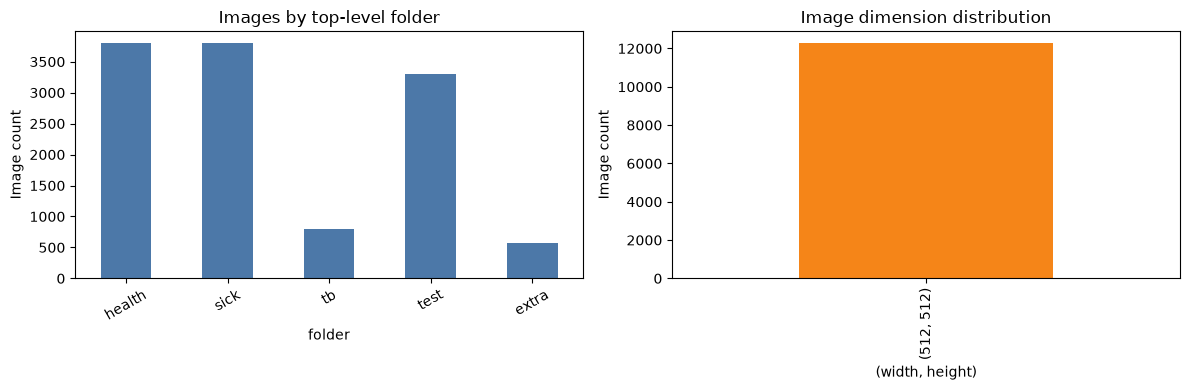

In [3]:
image_records = []
unreadable_images = []
for path in image_paths:
    relative = path.relative_to(IMAGE_ROOT)
    top_folder = relative.parts[0].casefold()
    label = 1 if top_folder == "tb" else 0 if top_folder in {"health", "sick"} else np.nan
    try:
        with Image.open(path) as image:
            image_records.append({
                "image_filename": relative.as_posix(),
                "folder": top_folder,
                "label": label,
                "width": image.width,
                "height": image.height,
                "format": image.format,
            })
            image.verify()
    except Exception as exc:
        unreadable_images.append((relative.as_posix(), str(exc)))
image_df = pd.DataFrame(image_records)
print(f"Readable images: {len(image_df):,} / {len(image_paths):,}")
print(f"Unreadable images: {len(unreadable_images):,}")
print("Dimensions:")
display(image_df.groupby(["width", "height"], dropna=False).size().rename("count").to_frame())
print("Known binary labels (health + sick -> non-TB; tb -> TB):")
display(image_df.dropna(subset=["label"]).groupby(["folder", "label"]).size().rename("count").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
image_df["folder"].value_counts().reindex(["health", "sick", "tb", "test", "extra"]).dropna().plot.bar(ax=axes[0], color="#4c78a8")
axes[0].set_title("Images by top-level folder")
axes[0].set_ylabel("Image count")
axes[0].tick_params(axis="x", rotation=30)
image_df.groupby(["width", "height"]).size().plot.bar(ax=axes[1], color="#f58518")
axes[1].set_title("Image dimension distribution")
axes[1].set_ylabel("Image count")
axes[1].set_xlabel("(width, height)")
plt.tight_layout()
plt.show()

## 3. Primary genomic table

The TB Portals genomics CSV contains specimen-level clinical/genomic annotations. Identifier and accession fields are excluded from the feature list, but retained for linkage diagnostics. Categorical frequency tables and missingness are descriptive only; `outcome` means treatment outcome, not TB-positive/negative label.

Primary genomics table: 9,333 rows x 40 columns
Non-ID feature fields: 33


,dtype,missing,missing_pct,distinct_non_null
gene_snp_mutations,string,3089,33.10,651
spoligotype_lineage,string,677,7.25,42
spoligotype_octal,string,390,4.18,235
mixed,string,390,4.18,2
bedaquiline,string,1,0.01,39
condition_id,string,0,0.00,8876
age_of_onset,string,0,0.00,87
sex,string,0,0.00,2
specimen_collection_date,string,0,0.00,358
specimen_identifier,string,0,0.00,9224


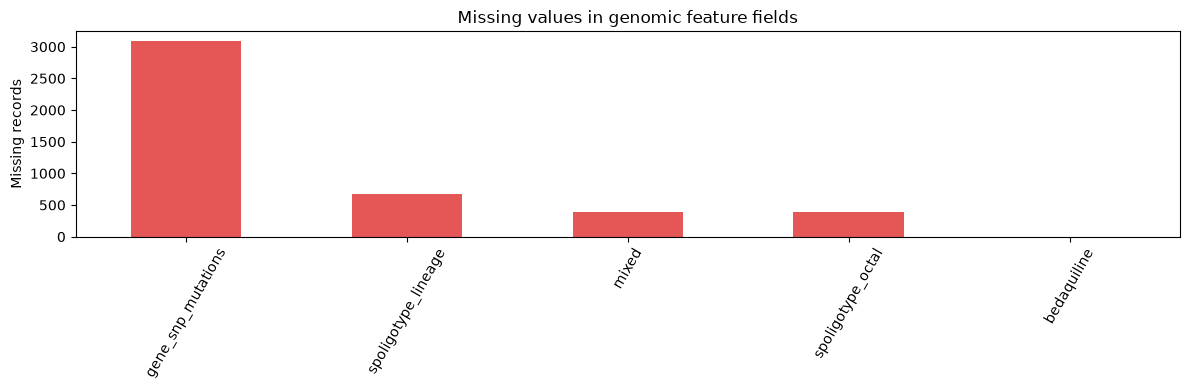

,count,mean,std,min,25%,50%,75%,max
age_of_onset,9333.0,42.890818,14.22252,2.0,32.0,42.0,53.0,93.0
num_drug_resistant_variants,9333.0,4.048752,3.592612,0.0,0.0,4.0,7.0,22.0
num_other_variants,9333.0,33.363763,55.650546,1.0,26.0,37.0,40.0,4357.0


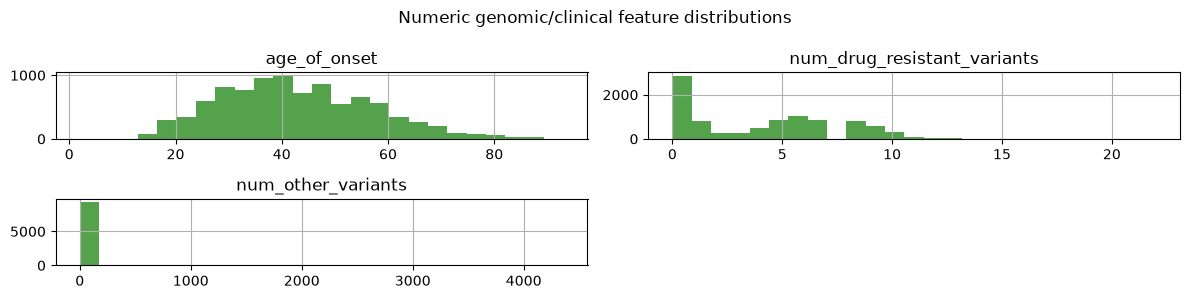


sex value counts:


,count
sex,
Male,6846
Female,2487



type_of_resistance value counts:


,count
type_of_resistance,
MDR non XDR,3903
Sensitive,3055
XDR,1080
Mono DR,588
Pre-XDR,495
Poly DR,212



outcome value counts:


,count
outcome,
Cured,5491
Completed,1421
Died,832
Lost to follow up,753
Failure,636
Palliative Care,88
Unknown,87
Still on treatment,25



main_lineage value counts:


,count
main_lineage,
lineage2,5074
lineage4,4053
lineage2;lineage4,134
lineage4;lineage6,16
lineage2;lineage6,13
lineage3,13
La1,10
lineage1,7
lineage3;lineage4,4



drug_resistance_type value counts:


,count
drug_resistance_type,
MDR-TB,3059
Sensitive,2873
Pre-XDR-TB,2029
Other,602
HR-TB,559
XDR-TB,106
RR-TB,105


In [4]:
genomics = pd.read_csv(GENOMICS_PATH, dtype="string", low_memory=False)
genomics.columns = (
    genomics.columns.str.strip().str.casefold()
    .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")
)
identifier_columns = {
    "condition_id", "specimen_id", "specimen_identifier", "sra_id",
    "ncbi_sra", "ncbi_bioproject", "ncbi_biosample",
}
feature_columns = [column for column in genomics.columns if column not in identifier_columns]
print(f"Primary genomics table: {genomics.shape[0]:,} rows x {genomics.shape[1]:,} columns")
print(f"Non-ID feature fields: {len(feature_columns)}")
display(pd.DataFrame({
    "dtype": genomics.dtypes.astype(str),
    "missing": genomics.isna().sum(),
    "missing_pct": (100 * genomics.isna().mean()).round(2),
    "distinct_non_null": genomics.nunique(dropna=True),
}).sort_values("missing", ascending=False))

missing_features = genomics[feature_columns].isna().sum().sort_values(ascending=False)
missing_features = missing_features[missing_features > 0]
if not missing_features.empty:
    ax = missing_features.plot.bar(figsize=(12, 4), color="#e45756")
    ax.set_title("Missing values in genomic feature fields")
    ax.set_ylabel("Missing records")
    ax.tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values in the non-ID feature fields.")

numeric_candidates = [
    column for column in ["age_of_onset", "num_drug_resistant_variants", "num_other_variants"]
    if column in genomics.columns
]
numeric_features = genomics[numeric_candidates].apply(pd.to_numeric, errors="coerce")
display(numeric_features.describe().T)
if numeric_candidates:
    numeric_features.hist(figsize=(12, 3), bins=25, color="#54a24b")
    plt.suptitle("Numeric genomic/clinical feature distributions")
    plt.tight_layout()
    plt.show()

for column in ["sex", "type_of_resistance", "outcome", "main_lineage", "drug_resistance_type"]:
    if column in genomics.columns:
        print(f"\n{column} value counts:")
        display(genomics[column].value_counts(dropna=False).head(25).to_frame("count"))

## 4. Sequenced DST table

This file stores repeated test/observation records (not one row per X-ray). It shares specimen identifiers with the primary genomic table, but it is not used as a surrogate image mapping. Merging it into a master table without a defined observation-selection rule would multiply sample rows.

In [5]:
dst = pd.read_csv(DST_PATH, dtype="string", low_memory=False)
dst.columns = (
    dst.columns.str.strip().str.casefold()
    .str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")
)
print(f"DST table: {dst.shape[0]:,} observation rows x {dst.shape[1]:,} columns")
for key in ["condition_id", "specimen_id"]:
    if key in dst.columns:
        print(f"{key}: {dst[key].nunique(dropna=True):,} unique non-null values")
print(f"Exact duplicate DST rows: {dst.duplicated().sum():,}")
common_specimens = set(genomics["specimen_id"].dropna()) & set(dst["specimen_id"].dropna())
print(f"Specimen IDs shared by the two genomic tables: {len(common_specimens):,}")
dst_missing = (100 * dst.isna().mean()).sort_values(ascending=False).head(15)
display(dst_missing.rename("missing_pct").to_frame())
for column in ["cultureresults", "firstcultureresults", "microscopyresults", "genexpertresults"]:
    if column in dst.columns:
        print(f"\n{column} values:")
        display(dst[column].value_counts(dropna=False).head(15).to_frame("count"))

DST table: 44,364 observation rows x 179 columns
condition_id: 8,875 unique non-null values
specimen_id: 9,221 unique non-null values


Exact duplicate DST rows: 0
Specimen IDs shared by the two genomic tables: 9,221


,missing_pct
bactec_mycobutin,100.0
bactec_imipenem_cilastatin,100.0
truenat_bedaquiline,100.0
truenat_moxifloxacin_0_25,100.0
truenat_moxifloxacin,100.0
truenat_pyrazinamide,100.0
truenat_levofloxacin,100.0
truenat_amikacin,100.0
truenat_capreomycin,100.0
truenat_ofloxacin,100.0



cultureresults values:


,count
cultureresults,
<NA>,32158
Positive,6326
20 to 100,1860
More than 200,1618
1 to 19,1144
100 to 200,877
Negative,308
Unknown result,44
Nonspecific microflora,27


...

,count
firstcultureresults,
<NA>,35535
Positive,5170
More than 200,1183
20 to 100,1147
1 to 19,620
100 to 200,557
Negative,109
Unknown result,21
Nonspecific microflora,21



microscopyresults values:


,count
microscopyresults,
<NA>,35170
Negative,3765
10 to 99 in 100 (1+),2182
1 to 9 in 1 (2+),1059
10 to 99 in 1 (3+),1045
1 to 9 in 100 (1-9/100),888
More than 99 in 1 (4+),161
Unknown data,47
Not done,39



genexpertresults values:


,count
genexpertresults,
<NA>,38545
{R},2853
{S},2830
"{R,S}",128
{I},7
{Ind},1


## 5. Official TBX11K labels, splits, and annotations

Use the official training/validation list rather than inferring labels from filenames. Folder names are the documented class mapping. The test list is retained as unknown-label data and is not included in class statistics.

,images,tb,health,sick,extra,test
split,,,,,,
TBX11K_train.txt,6600,600,3000,3000,0,0
TBX11K_val.txt,1800,200,800,800,0,0
TBX11K_trainval.txt,8400,800,3800,3800,0,0
all_train.txt,6888,600,3000,3000,288,0
all_val.txt,2088,200,800,800,288,0
all_test.txt,3302,0,0,0,0,3302


README-described TBX11K + additional-source total: 12,306
Observed all_train + all_val + all_test entries: 12,278 (12,278 unique)
Inventory discrepancy vs README-described source totals: -28; review source provenance before release.
Official TBX11K trainval binary label counts: {'non_tb': 7600, 'tb': 800}
Known-label TB fraction: 0.0952


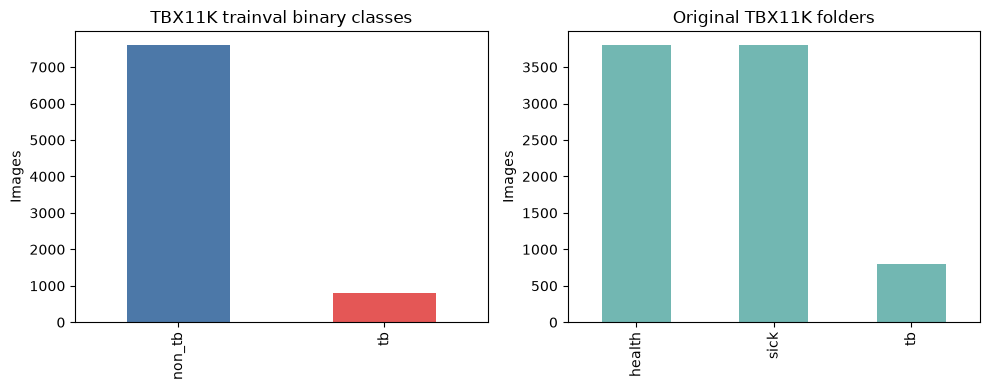

XML lesion annotations: 800; JSON annotation files: 10


,images,annotations,categories
file,,,
TBX11K_train.json,6600,902,3
TBX11K_train_only_tb.json,599,902,3
TBX11K_trainval.json,8400,1211,3
TBX11K_trainval_only_tb.json,799,1211,3
TBX11K_val.json,1800,309,3
TBX11K_val_only_tb.json,200,309,3
all_test.json,3302,0,3
all_train.json,6888,902,3
all_trainval.json,8976,1211,3


In [6]:
def read_split(name: str) -> list[str]:
    path = LIST_ROOT / name
    if not path.is_file():
        warnings.warn(f"Missing split list: {path}")
        return []
    return [line.strip().replace("\\", "/") for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

split_names = ["TBX11K_train.txt", "TBX11K_val.txt", "TBX11K_trainval.txt", "all_train.txt", "all_val.txt", "all_test.txt"]
split_rows = []
for split_name in split_names:
    entries = read_split(split_name)
    counts = Counter(entry.split("/")[0].casefold() for entry in entries)
    split_rows.append({"split": split_name, "images": len(entries), **counts})
split_summary = pd.DataFrame(split_rows).set_index("split").fillna(0).astype(int)
display(split_summary)

trainval_entries = read_split("TBX11K_trainval.txt")
trainval_counts = Counter(entry.split("/")[0].casefold() for entry in trainval_entries)
labeled_counts = {
    "non_tb": trainval_counts.get("health", 0) + trainval_counts.get("sick", 0),
    "tb": trainval_counts.get("tb", 0),
}
combined_lists = [read_split(name) for name in ["all_train.txt", "all_val.txt", "all_test.txt"]]
combined_entries = [entry for entries in combined_lists for entry in entries]
readme_expected_total = 11200 + 156 + 150 + 138 + 662
print(f"README-described TBX11K + additional-source total: {readme_expected_total:,}")
print(f"Observed all_train + all_val + all_test entries: {len(combined_entries):,} ({len(set(combined_entries)):,} unique)")
print(f"Inventory discrepancy vs README-described source totals: {len(set(combined_entries)) - readme_expected_total:+,}; review source provenance before release.")
print("Official TBX11K trainval binary label counts:", labeled_counts)
print("Known-label TB fraction:", round(labeled_counts["tb"] / sum(labeled_counts.values()), 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pd.Series(labeled_counts).plot.bar(ax=axes[0], color=["#4c78a8", "#e45756"])
axes[0].set_title("TBX11K trainval binary classes")
axes[0].set_ylabel("Images")
trainval_paths = pd.Series([entry.split("/")[0] for entry in trainval_entries]).value_counts()
trainval_paths.reindex(["health", "sick", "tb"]).plot.bar(ax=axes[1], color="#72b7b2")
axes[1].set_title("Original TBX11K folders")
axes[1].set_ylabel("Images")
plt.tight_layout()
plt.show()

xml_files = list((ANNOTATION_ROOT / "xml").glob("*.xml")) if (ANNOTATION_ROOT / "xml").is_dir() else []
json_files = list((ANNOTATION_ROOT / "json").glob("*.json")) if (ANNOTATION_ROOT / "json").is_dir() else []
print(f"XML lesion annotations: {len(xml_files):,}; JSON annotation files: {len(json_files):,}")
json_summary = []
for path in json_files:
    try:
        content = json.loads(path.read_text(encoding="utf-8"))
        json_summary.append({
            "file": path.name,
            "images": len(content.get("images", [])),
            "annotations": len(content.get("annotations", [])),
            "categories": len(content.get("categories", [])),
        })
    except (OSError, json.JSONDecodeError) as exc:
        print(f"Could not parse {path.name}: {exc}")
display(pd.DataFrame(json_summary).set_index("file").sort_index())

## 6. Patient-level checks, modality linkage, and correlation feasibility

The image sources do not expose patient IDs; TBX11K image names are dataset image IDs. Genomic rows use TB Portals specimen/accession identifiers. A matching filename stem is not a clinical crosswalk, but checking for exact stem overlap is a useful negative diagnostic. Patient-level multimodal analyses must remain unavailable until an authoritative mapping is added.

In [7]:
image_stem_list = [path.stem.casefold() for path in image_paths]
image_stems = set(image_stem_list)
identifier_candidates = [
    column for column in ["condition_id", "specimen_id", "specimen_identifier", "ncbi_biosample", "sra_id", "ncbi_sra"]
    if column in genomics.columns
]
stem_intersections = {}
for column in identifier_candidates:
    genomic_ids = set(genomics[column].dropna().astype(str).str.casefold())
    stem_intersections[column] = len(genomic_ids & image_stems)
display(pd.Series(stem_intersections, name="exact_image_stem_matches").to_frame())

for column in ["specimen_identifier", "specimen_id", "condition_id"]:
    if column in genomics.columns:
        duplicate_rows = int(genomics[column].duplicated().sum())
        print(f"Genomic {column}: {genomics[column].nunique():,} distinct; {duplicate_rows:,} repeated rows")
print(f"Duplicate image filename stems across tree: {len(image_stem_list) - len(image_stems):,}")
print("Images per patient: not measurable; image-level patient IDs are absent.")

mapping_path = TB_ROOT / "image_genomic_mapping.csv"
if mapping_path.is_file():
    mapping = pd.read_csv(mapping_path, dtype="string")
    mapping.columns = mapping.columns.str.strip().str.casefold()
    if not {"patient_id", "image_filename"}.issubset(mapping.columns):
        raise ValueError("Explicit mapping must include patient_id and image_filename columns.")
    if "specimen_identifier" not in genomics.columns:
        raise ValueError("Default mapping key specimen_identifier is not available.")
    def mapped_binary_label(row):
        image_path = (IMAGE_ROOT / str(row["image_filename"]).replace(chr(92), "/")).resolve()
        try:
            relative_image = image_path.relative_to(IMAGE_ROOT.resolve())
        except ValueError:
            return np.nan
        if not image_path.is_file():
            return np.nan
        folder_label = {"tb": 1, "health": 0, "sick": 0}.get(relative_image.parts[0].casefold())
        raw_label = row.get("label")
        if raw_label is None or pd.isna(raw_label) or not str(raw_label).strip():
            return folder_label
        label_text = str(raw_label).strip().casefold().replace("-", " ").replace("_", " ")
        if label_text in {"1", "tb", "positive", "active tb", "tb positive"}:
            supplied_label = 1
        elif label_text in {"0", "non tb", "negative", "healthy", "sick", "tb negative"}:
            supplied_label = 0
        else:
            raise ValueError(f"Unsupported mapped label: {raw_label!r}")
        if folder_label is not None and supplied_label != folder_label:
            raise ValueError(f"Mapping label conflicts with image folder: {image_path}")
        return supplied_label
    mapping["label"] = mapping.apply(mapped_binary_label, axis=1)
    mapping["patient_id"] = mapping["patient_id"].astype("string").str.strip()
    mapping = mapping.dropna(subset=["patient_id", "label"])
    mapping = mapping.loc[mapping["patient_id"] != ""]
    genomic_matches = genomics.loc[genomics["specimen_identifier"].isin(mapping["patient_id"])]
    if genomic_matches["specimen_identifier"].duplicated().any():
        raise ValueError("Crosswalk references duplicated specimen_identifier values; resolve them before joining.")
    mapped = mapping.merge(
        genomics,
        left_on="patient_id",
        right_on="specimen_identifier",
        how="inner",
        validate="many_to_one",
    )
    print(f"Explicit crosswalk rows: {len(mapping):,}; joined rows: {len(mapped):,}")
    if not mapped.empty:
        numeric_genomics = mapped[feature_columns].apply(pd.to_numeric, errors="coerce")
        correlations = numeric_genomics.corrwith(mapped["label"])
        display(correlations.dropna().sort_values(key=lambda values: values.abs(), ascending=False).to_frame("label_correlation"))
    else:
        print("No valid binary image labels in the crosswalk; correlation skipped.")
else:
    print("No image_genomic_mapping.csv found: paired patient analysis and genomic/TB-label correlation are not statistically valid and are skipped.")

,exact_image_stem_matches
condition_id,0
specimen_id,0
specimen_identifier,0
ncbi_biosample,0
sra_id,0
ncbi_sra,0


Genomic specimen_identifier: 9,224 distinct; 109 repeated rows
Genomic specimen_id: 9,224 distinct; 109 repeated rows
Genomic condition_id: 8,876 distinct; 457 repeated rows
Duplicate image filename stems across tree: 0
Images per patient: not measurable; image-level patient IDs are absent.
No image_genomic_mapping.csv found: paired patient analysis and genomic/TB-label correlation are not statistically valid and are skipped.


## Findings and preparation recommendations

- **X-rays:** the inventory contains 12,278 readable images. All are 512 x 512 pixels. TBX11K official train/validation lists contain 8,400 known-label images: 3,800 healthy + 3,800 sick-but-non-TB (7,600 non-TB) and 800 TB. The 3,302 `test/unknown_*.png` images have no released test labels. The 576 `extra` images have source/split folders but no class label in the local folder structure. The included README describes 11,200 TBX11K images plus 1,106 images from other sources (12,306 total), while the combined local split lists contain 12,278 unique paths, a 28-image discrepancy to resolve with source provenance.
- **Genomics:** `TB_Portals_Genomics_March_2026.csv` has 9,333 records and 40 columns, including 33 non-identifier feature fields. Missingness is concentrated in `gene_snp_mutations`, `spoligotype_lineage`, `mixed`, and `spoligotype_octal`; no missing values are encoded as evidence of a negative genotype.
- **DST:** the separate sequenced DST CSV has 44,364 repeated observation rows and 179 columns. It shares specimen IDs with the genomics table, but it is not a patient-to-image mapping and should not be naively joined as if one row represented one person.
- **Labels and association:** the genomic table contains treatment outcomes/resistance and does not provide a negative-TB genomic cohort. There is no valid genomic-feature/TB-image-label correlation without a verified crosswalk and a comparable label definition.
- **Patient-level analysis:** the image set has no patient identifier field. The genomic table repeats 109 `specimen_identifier` values; review those records before selecting a patient-level genomic unit. The DST table is also observation-level.
- **Next step:** obtain a consented/authorized crosswalk with `patient_id` and `image_filename` (and a verified label for images without a documented label folder). Until then, `data/processed/tb_cleaned.csv` should remain schema-only rather than contain fabricated multimodal pairs. Preserve official train/validation/test boundaries and document dataset provenance before federated partitioning.